# Alanine dipeptide in vacuum: TPS set-up with ops-setup

`AlanineDipeptideVacuumSetup` builds the whole OPS set-up from a JSON config, which by default is the packaged
`config_alanine_dipeptide_vacuum.json`:
- **System:** openmmtools `AlanineDipeptideVacuum` (amber ff96, HBonds constraints), no box.
- **Dynamics:** VVVR integrator at 300 K, 2 fs, friction 1/ps, 10 steps per frame (0.02 ps per frame).
- **States:** boxes in the backbone dihedrals φ, ψ:
  - **C7eq:** φ ∈ [−180°, −50°], ψ ∈ [30°, 210°] (ψ wraps through ±180°);
  - **C7ax:** φ ∈ [40°, 90°], ψ ∈ [−100°, −40°].

  The ranges come from 300 K MD in both basins. C7ax is metastable on a ~ns scale, and C7eq → C7ax is much rarer.
- **Descriptors:** sin/cos of the four backbone dihedrals (`transform_functions.descriptor_sincos`).

In [1]:
import numpy as np, matplotlib.pyplot as plt, openpathsampling as paths
from ops_setup.systems.examples.alanine_dipeptide import AlanineDipeptideVacuumSetup, transform_functions as tf
ad = AlanineDipeptideVacuumSetup(print_config_flag=False)
print("states:", [s.name for s in ad.states], "| beta:", ad.beta, "| kT:", ad.kT, "| frame:", ad.md_engine.snapshot_timestep)

****** PyMBAR will use 64-bit JAX! *******
* JAX is currently set to 32-bit bitsize *
* which is its default.                  *
*                                        *
* PyMBAR requires 64-bit mode and WILL   *
* enable JAX's 64-bit mode when called.  *
*                                        *
* This MAY cause problems with other     *
* Uses of JAX in the same code.          *
******************************************



extracting config
Setting up VVVR integrator...
Setting up VVVR integrator...
Setting up OpenMM engine on CPU platform...
states: ['C7eq', 'C7ax'] | beta: 2.41432350534664e+20 /J | kT: 2.494338785445972 kJ/mol | frame: 0.02 ps


## Initial path

As in the OPS alanine dipeptide tutorial: MD at 800 K from the template until both states are visited, then the first
transition is cut out. Shooting at 300 K redraws the velocities.

hot trajectory 831 frames; first transition 105 frames, ['C7eq'] -> ['C7ax']


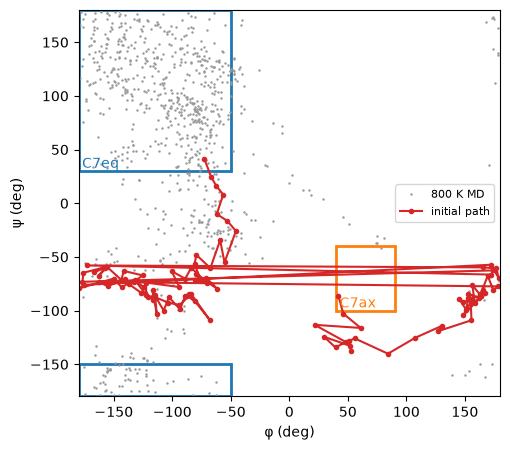

In [2]:
hot = ad.generate_initial_path(seed=1, trim=False)
init = ad.generate_initial_path(seed=1)
print(f"hot trajectory {len(hot)} frames; first transition {len(init)} frames, "
      f"{[s.name for s in ad.states if s(init[0])]} -> {[s.name for s in ad.states if s(init[-1])]}")
d_hot, d_init = np.degrees(tf.backbone_dihedrals(hot)), np.degrees(tf.backbone_dihedrals(init))
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot(d_hot[:, 0], d_hot[:, 1], ".", ms=1.5, color="0.6", label="800 K MD")
ax.plot(d_init[:, 0], d_init[:, 1], "o-", ms=3, color="C3", label="initial path")
for name, col in zip(ad.state_names, ("C0", "C1")):
    (p0, p1), (s0, s1) = ad.state_ranges[name]
    for lo, hi in ((s0, min(s1, 180)), (-180, s1 - 360) if s1 > 180 else (None, None)):
        if lo is not None:
            ax.add_patch(plt.Rectangle((p0, lo), p1 - p0, hi - lo, fill=False, color=col, lw=2))
    ax.text(p0 + 3, s0 + 3, name, color=col)
ax.set_xlim(-180, 180); ax.set_ylim(-180, 180); ax.set_xlabel("φ (deg)"); ax.set_ylabel("ψ (deg)"); ax.legend(fontsize=8)
plt.tight_layout()

## A short TPS run

Two-way shooting with a uniform selector, 150 steps. This checks the set-up; it is not a converged TPS run. The
first path comes from 800 K MD, so early shots at 300 K mostly fall back into the state they started from.
C7eq → C7ax is a rare event, so expect an acceptance of only a few percent at first.

In [3]:
import tempfile, os
paths.PathMover.engine = ad.md_engine
network = paths.TPSNetwork(initial_states=ad.states[0], final_states=ad.states[1])
scheme = ad.create_move_scheme(network, scheme_type="TwoWay")
init_conditions = scheme.initial_conditions_from_trajectories(init)
storage = paths.Storage(os.path.join(tempfile.mkdtemp(), "ad_tps.nc"), "w", template=ad.template)
sampler = paths.PathSampling(storage=storage, move_scheme=scheme, sample_set=init_conditions)
sampler.live_visualizer = None
sampler.run(150)
lengths = [len(step.active[0].trajectory) for step in storage.steps]
acc = np.mean([step.change.accepted for step in storage.steps[1:]])
print(f"150 TPS steps: acceptance {acc:.2f}, path lengths {min(lengths)}-{max(lengths)} frames "
      f"({0.02 * np.median(lengths):.2f} ps median)")
storage.close()

Working on Monte Carlo cycle number 150
Running for 26 seconds -  0.18 seconds per step
Estimated time remaining: 0 seconds


DONE! Completed 150 Monte Carlo cycles.


150 TPS steps: acceptance 0.09, path lengths 35-131 frames (1.62 ps median)
